# Does it keep oscillating? A non-dimensional map in $\dot m_{max}$

**What this notebook does.** It answers the question "for which valve capacity $\dot m_{max}$ does the expander keep oscillating?" and shows how the answer collapses onto one dimensionless number. Everything is computed with the averaged (two-timescale) model from `analytic_vs_numerical_check.ipynb`, then spot-checked against the full simulation at 8 points.

**Headlines.**

1. Your proposed group $\dot m_{max}/(\bar M\,\omega)$ — a mass flow rate over (gas mass × frequency) — is the right core. Dressed with three factors it becomes the number that decides ignition: $\Pi = \gamma_E\, Q\, L\, \dfrac{\bar P}{\Delta P_{max}}\, \dfrac{\tilde G\, \dot m_{max}}{\bar M_{cv}\,\omega}$, and small oscillations grow iff $\Pi > 1$.

2. **Within one geometry, $\dot m_{max}$ and the damping $b$ enter the averaged dynamics only through their ratio.** Raising $\dot m_{max}$ is *exactly* equivalent to lowering $b$ (proved and demonstrated below, overlay agrees to $10^{-2}$ Pa). So the sustain/die boundary is a sharp critical value of $Q\,\dot m_{max}/(\bar M\omega)$ — and if the *undamped* system dies, **no** $\dot m_{max}$ can save it.

3. That second case is real: of your five families only $V_{0,cv}=10^{-4}$ has a boundary ($\dot m_{max,crit} \approx 3.8\times10^{-4}$ kg/s; your $10^{-3}$ sits a factor 2.7 above it, which is why it's the one that runs). Families 2–5 die at **every** $\dot m_{max}$, even with $b=0$: they lose a race — the mean pressure crosses the narrow pumping window before the amplitude can grow enough to hold it there. The critical geometry is $V_{0,cv}^{*} \approx 1.95\times10^{-4}$ m³, just below family 2.

4. Sweeping $V_{0,cv}$ finely below $V^{*}$ gives a family of boundaries. The raw group $\dot m_{max,crit}/(\bar M\omega)$ spreads by a factor **160**; the dressed $\Pi_{crit}$ collapses to $\approx 1$ with a $1/(1-V_{0,cv}/V^{*})$ divergence: $\Pi_{crit}\,(1-V_{0,cv}/V^{*}) \approx 1$ within ±15% over the whole range.

Runtime: about 3 minutes (the sweeps and 8 full simulations run live).

## 1. The dimensionless number

Start from the growth rate of the averaged model (packet notes, eqs. (22)–(23)): $\lambda = -\dfrac{b}{2m} + \dfrac{g}{2}\,\dfrac{k_{cv}}{k_{cv}+k_{pass}}$, where $g$ is the valve feedback, $g = -\dfrac{C_f}{\bar V_{cv}}\left(T_{in} N_{in} + \bar T N_{out}\right)$, and $N$ are the flow-slope describing functions (at small amplitude, $N = F'$, the local slope of the valve curve).

Non-dimensionalize $g$. The valve law $F = \dot m_{max}(1-u)\sqrt{u}$, $u = \Delta P/\Delta P_{max}$, has slope $F' = \dfrac{\dot m_{max}}{\Delta P_{max}}\,\tilde N(u)$ with $\tilde N(u) = \dfrac{1-3u}{2\sqrt{u}}$ dimensionless. Using $C_f = \gamma_E R$ (with $\gamma_E = 1 + R/c_v$, this notebook's effective CV gamma) and the ideal gas law $R\bar T/\bar V_{cv} = \bar P/\bar M_{cv}$:

$g = \gamma_E\,\dfrac{\bar P}{\Delta P_{max}}\,\dfrac{\dot m_{max}}{\bar M_{cv}}\,\tilde G, \qquad \tilde G = -\left[\dfrac{T_{in}}{\bar T}\tilde N(u_{in}) + \tilde N(u_{out})\right].$

$\tilde G$ is an order-one shape factor. At the launch state ($\bar P = P_0$): $u_{in}=0.545$, $u_{out}=0.655$ — both valves sit past the flow peak $u=1/3$, both slopes are negative, so $\tilde G = +1.027 > 0$: pumping.

Growth ($\lambda > 0$) requires $\dfrac{g}{2}L > \dfrac{b}{2m}$ with $L = \dfrac{k_{cv}}{k_{cv}+k_{pass}}$, i.e. $g L \dfrac{m}{b} > 1$. With the quality factor $Q = m\omega/b$ this is

$\boxed{\;\Pi \equiv \gamma_E\, Q\, L\, \dfrac{\bar P}{\Delta P_{max}}\, \dfrac{\tilde G\,\dot m_{max}}{\bar M_{cv}\,\omega} \;>\; 1\;}$

Your group $\dot m_{max}/(\bar M \omega)$ is the engine — "valve throughput per radian of oscillation, measured in chamber masses." The three dressings say how efficiently that throughput is converted to growth: $\bar P/\Delta P_{max}$ (pressure leverage — a stiff valve curve reacts strongly to a small pressure swing; here 12.5), $L$ (the control volume's share of the total gas spring — only the CV side of the oscillation feels the valves), and $Q$ (an oscillator that loses little per cycle needs little pumping to beat its damping).

## 2. An exact rescaling: $\dot m_{max}$ is (inverse) damping

In the averaged system $(\bar M, \bar P, a)$ every term on the right-hand side is proportional to $\dot m_{max}$ — the fluxes $F_0$, the pumping $g$ (hence the $g$-parts of $\lambda$ and of $d\bar P/dt$), and the chirp $\dot\omega \propto d\bar P/dt$ — **except** the linear damping $-\,(b/2m)\,a$. The initial condition ($a_0 = v_0/\omega_0$) contains no $\dot m_{max}$ either. Therefore the map $(\dot m_{max},\, b) \to (s\,\dot m_{max},\, s\,b)$ sends trajectories to themselves with time rescaled $t \to t/s$. Two consequences:

- **Within a family the outcome depends on $(\dot m_{max}, b)$ only through $\dot m_{max}/b$** — equivalently through $Q\,\dot m_{max}/(\bar M\omega)$, your group dressed with $Q$. A sweep in valve capacity *is* a sweep in damping.
- **The limit $\dot m_{max}\to\infty$ is the undamped ($b=0$) system.** If the undamped system fails to sustain, no valve capacity whatsoever rescues that geometry. This is what happens to families 2–5.

Section 5 demonstrates the rescaling numerically: trajectories at $s=1$ and $s=4$ overlaid in rescaled time agree to about $10^{-2}$ Pa.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import butter, filtfilt, hilbert

# ---- constants: identical to V_passive_sweep_energy_balance.ipynb ----
gamma = 1.41
R = 287.0
cp, cv = 1050.0, 744.0
P_in, P_out, P0 = 6e5, 5.45e5, 5.75e5
T_in = 300.0; T0 = T_in
A_neck = 2.85e-4
m_gas = 0.0015
b_gas = 0.005
zeta = 0.6
dP_max = (P_in - P_out) / (2 * zeta)
m_max = 0.001                      # swept below; this is your baseline value
x0, v0 = 0.0, 5.0
V0_pass = 2e-4
V0_cv_values = np.linspace(1e-4, 5e-4, 5)

gamma_E = 1.0 + R / cv             # CV effective gamma (R != cp - cv here)
Cf = cp * R / cv                   # flux coefficient in the pressure equation

BLUE, ORANGE, AQUA, INK, INK2 = '#2a78d6', '#eb6834', '#1baf7a', '#0b0b0b', '#52514e'

def reed_flow(dP):
    u = dP / dP_max
    if 0.0 < dP < dP_max:
        return m_max * (1 - u) * np.sqrt(u)
    if dP <= 0.0:
        return -m_max * (1 - u) * np.sqrt(abs(u))
    return 0.0

def reed_flow_vec(dP):
    dP = np.asarray(dP, dtype=float)
    u = dP / dP_max
    out = np.zeros_like(dP)
    mo = (dP > 0) & (dP < dP_max)
    mr = dP <= 0
    out[mo] = m_max * (1 - u[mo]) * np.sqrt(u[mo])
    out[mr] = -m_max * (1 - u[mr]) * np.sqrt(np.abs(u[mr]))
    return out

# ---- full model (verbatim from the sweep notebook) ----
def full_ode(t, y, V0_cv):
    x, v, M, E = y
    Vc = V0_cv + x * A_neck
    T = E / (cv * M)
    P = M * R * T / Vc
    Vp = V0_pass - x * A_neck
    Pp = P0 * (V0_pass / Vp)**gamma
    mi = reed_flow(P_in - P)
    mo = reed_flow(P - P_out)
    return [v,
            (P - Pp) * A_neck / m_gas - (b_gas / m_gas) * v,
            mi - mo,
            -P * A_neck * v + mi * cp * T_in - mo * cp * T]

def run_full(V0_cv, t_end=1.0, n_eval=20000, rtol=1e-6, atol=1e-8):
    M0 = P0 * V0_cv / (R * T0)
    y0 = [x0, v0, M0, cv * M0 * T0]
    te = np.linspace(0.0, t_end, n_eval)
    sol = solve_ivp(full_ode, (0.0, t_end), y0, t_eval=te, args=(V0_cv,),
                    method='RK45', rtol=rtol, atol=atol)
    x, v, M, E = sol.y
    Vc = V0_cv + x * A_neck
    T = E / (cv * M)
    P = M * R * T / Vc
    return sol.t, P

# ---- averaged (two-timescale) model, as validated in the previous notebook ----
PSI = np.linspace(0, 2 * np.pi, 513)[:-1]
CPS = np.cos(PSI)

def F0F1(dPbar, delta):
    vals = reed_flow_vec(dPbar + delta * CPS)
    return vals.mean(), 2.0 * (vals * CPS).mean()

def geom(Pb, V0_cv):
    Vp = V0_pass * (P0 / Pb)**(1.0 / gamma)
    Vc = V0_cv + (V0_pass - Vp)
    kcv = gamma_E * Pb * A_neck**2 / Vc
    kp = gamma * Pb * A_neck**2 / Vp
    w = np.sqrt((kcv + kp) / m_gas)
    return Vp, Vc, kcv, kp, w

def slow_rhs(t, y, V0_cv):
    Mb, Pb, a = y
    a = max(a, 0.0)
    Vp, Vc, kcv, kp, w = geom(Pb, V0_cv)
    Tb = Pb * Vc / (Mb * R)
    delta = kcv * a / A_neck
    if delta > 1.0:
        F0i, F1i = F0F1(P_in - Pb, delta)
        F0o, F1o = F0F1(Pb - P_out, delta)
        Ni, No = F1i / delta, F1o / delta
    else:
        h = 1.0
        F0i, F0o = reed_flow(P_in - Pb), reed_flow(Pb - P_out)
        Ni = (reed_flow(P_in - Pb + h) - reed_flow(P_in - Pb - h)) / (2 * h)
        No = (reed_flow(Pb - P_out + h) - reed_flow(Pb - P_out - h)) / (2 * h)
    g = -(Cf / Vc) * (T_in * Ni + Tb * No)
    lam = -b_gas / (2 * m_gas) + 0.5 * g * kcv / (kcv + kp)
    dMb = F0i - F0o
    dPb = (Cf * (T_in * F0i - Tb * F0o) - Vc * g * delta**2 / (2 * Pb)) \
          / (Vc + (gamma_E / gamma) * Vp)
    dPp = 1e-4 * max(abs(dPb), 1.0)
    wdot = (geom(Pb + dPp, V0_cv)[4] - w) / dPp * dPb
    da = lam * a - (wdot / (2 * w)) * a
    if a <= 1e-10 and da < 0:
        da = 0.0
    return [dMb, dPb, da]

def extract(t, P):
    fs = 1.0 / np.median(np.diff(t))
    bb, aa = butter(4, 12.0 / (fs / 2), 'low')
    Pbar = filtfilt(bb, aa, P)
    env = filtfilt(bb, aa, np.abs(hilbert(P - Pbar)))
    return Pbar, env

print('model loaded: dP_max = %.3f bar, gamma_E = %.4f' % (dP_max / 1e5, gamma_E))

model loaded: dP_max = 0.458 bar, gamma_E = 1.3858


In [2]:
# ---- sustain/die classifier (averaged model) and boundary finder ----
DELTA_SUST = 1.0e3          # Pa: oscillation amplitude above this at the end counts as sustained

def classify(V0, mdot):
    """Integrate the averaged model at m_max = mdot; return (sustained, delta_end, Pbar_end).

    Chunked integration, each chunk 1.5 fill times (fill time = M_tot/mdot), up to
    9 fill times.  Early exits: dead when frozen at P_in with no amplitude;
    sustained when settled (|dPbar/dt| small) with amplitude above threshold.
    """
    global m_max
    m_max = mdot
    M0 = P0 * V0 / (R * T0)
    Mtot = P0 * (V0 + V0_pass) / (R * T0)
    tf = 1.5 * Mtot / mdot
    y = [M0, P0, v0 / geom(P0, V0)[4]]
    dP_scale = Cf * T_in * mdot / (V0 + V0_pass)
    t0 = 0.0
    for k in range(6):
        sol = solve_ivp(slow_rhs, (t0, t0 + tf), y, args=(V0,),
                        method='LSODA', rtol=1e-6, atol=[1e-12, 1e-2, 1e-12],
                        max_step=tf / 200.0)
        y = sol.y[:, -1]
        t0 = sol.t[-1]
        Mb, Pb, a = y
        delta = geom(Pb, V0)[2] * a / A_neck
        if delta < 1.0 and Pb > P_in - 1e3:
            return False, delta, Pb                    # frozen at full charge
        if delta > DELTA_SUST and abs(slow_rhs(t0, y, V0)[1]) < 0.01 * dP_scale:
            return True, delta, Pb                     # settled on the limit cycle
    return (delta > DELTA_SUST), delta, Pb

def find_boundary(V0, lo=1e-5, hi=0.3, nscan=13, tol_rel=1e-3):
    """Geometric scan (checks the boundary is single) then bisection in log mdot."""
    grid = np.geomspace(lo, hi, nscan)
    verd = np.array([classify(V0, md)[0] for md in grid])
    assert verd.any() and not verd.all(), 'no boundary in scan range'
    assert np.sum(verd[1:] != verd[:-1]) == 1, 'outcome not monotone in mdot'
    i = int(np.argmax(verd))
    a_lo, a_hi = grid[i - 1], grid[i]
    while (a_hi - a_lo) / a_hi > tol_rel:
        mid = float(np.sqrt(a_lo * a_hi))
        if classify(V0, mid)[0]:
            a_hi = mid
        else:
            a_lo = mid
    return float(np.sqrt(a_lo * a_hi))

def fprime_u(u):
    return (1.0 - 3.0 * u) / (2.0 * np.sqrt(u))

def family_numbers(V0):
    """The dressing factors of Pi, evaluated at the launch state (P0, T0)."""
    Vp, Vc, kcv, kp, w0 = geom(P0, V0)
    Q = m_gas * w0 / b_gas
    L = kcv / (kcv + kp)
    Mcv = P0 * V0 / (R * T0)
    Mtot = P0 * (V0 + V0_pass) / (R * T0)
    u_in = (P_in - P0) / dP_max
    u_out = (P0 - P_out) / dP_max
    Gt = -((T_in / T0) * fprime_u(u_in) + fprime_u(u_out))
    return dict(w0=w0, Q=Q, L=L, Mcv=Mcv, Mtot=Mtot, Gt=Gt)

def Pi_raw(V0, mdot, fn=None):
    fn = fn or family_numbers(V0)
    return mdot / (fn['Mtot'] * fn['w0'])

def Pi_dressed(V0, mdot, fn=None):
    fn = fn or family_numbers(V0)
    return gamma_E * fn['Q'] * fn['L'] * (P0 / dP_max) * mdot * fn['Gt'] / (fn['Mcv'] * fn['w0'])

fn0 = family_numbers(1e-4)
print('launch-state shape factor G = %.4f  (u_in = %.3f, u_out = %.3f)'
      % (fn0['Gt'], (P_in - P0) / dP_max, (P0 - P_out) / dP_max))

launch-state shape factor G = 1.0264  (u_in = 0.545, u_out = 0.655)


## 3. The map you asked for: oscillating vs $\dot m_{max}/(\bar M\,\omega)$

For each of your five $V_{0,cv}$ families, scan $\dot m_{max}$ over 3×10⁻⁵ … 10⁻² kg/s and record whether the averaged model still oscillates at long time (≥ 9 fill times, amplitude above 10³ Pa). The x-axis is the raw group $\Pi_1 = \dot m_{max}/(\bar M_{tot}\,\omega_0)$ with $\bar M_{tot} = P_0(V_{0,cv}+V_{0,pass})/(R T_0)$ the total initial gas mass and $\omega_0$ the launch angular frequency.

Only family 1 has a boundary. Families 2–5 are dead **at every point of the scan** — including $\dot m_{max}$ six times your baseline. By the rescaling theorem this is final: their undamped limit dies, so no valve capacity sustains them (the b = 0 check is printed below).

In [3]:
import time
tic = time.time()
scan = np.geomspace(3e-5, 1e-2, 14)
family_verdicts = {}
for V0 in V0_cv_values:
    family_verdicts[V0] = np.array([classify(V0, md)[0] for md in scan])
    print('V0_cv = %.0e:  %s' % (V0, ''.join('S' if s else '.' for s in family_verdicts[V0])))

mdot_crit_f1 = find_boundary(1e-4)
print('family 1 boundary: mdot_crit = %.4e kg/s   (baseline 1e-3 is %.2fx above)'
      % (mdot_crit_f1, 1e-3 / mdot_crit_f1))

# undamped check for families 2-5: mdot -> infinity limit
b_save, b_gas = b_gas, 1e-8
undamped = {V0: classify(V0, 1e-3)[0] for V0 in V0_cv_values[1:]}
b_gas = b_save
print('undamped (b = 0) verdicts, families 2-5:',
      ['SUST' if v else 'dead' for v in undamped.values()])
print('[%.0f s]' % (time.time() - tic))

V0_cv = 1e-04:  ......SSSSSSSS
V0_cv = 2e-04:  ..............
V0_cv = 3e-04:  ..............
V0_cv = 4e-04:  ..............
V0_cv = 5e-04:  ..............
family 1 boundary: mdot_crit = 3.7638e-04 kg/s   (baseline 1e-3 is 2.66x above)
undamped (b = 0) verdicts, families 2-5: ['dead', 'dead', 'dead', 'dead']
[22 s]


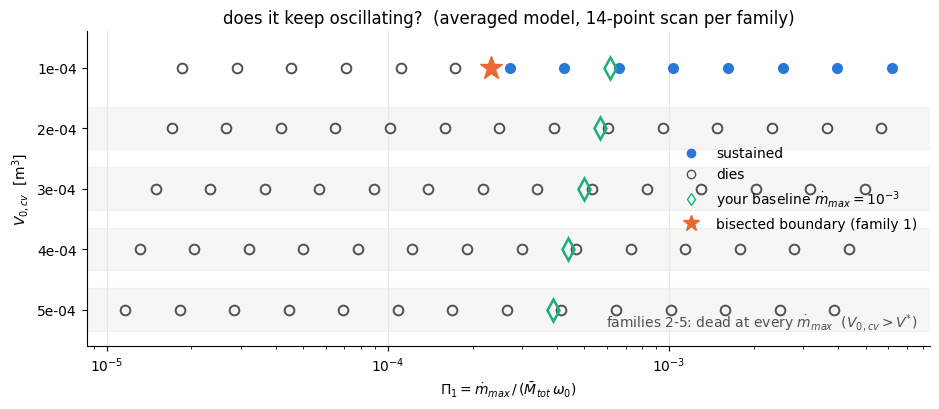

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for i, V0 in enumerate(V0_cv_values):
    fn = family_numbers(V0)
    x = scan / (fn['Mtot'] * fn['w0'])
    v = family_verdicts[V0]
    ax.plot(x[~v], np.full((~v).sum(), i), 'o', mfc='none', mec=INK2, ms=7, mew=1.4)
    ax.plot(x[v], np.full(v.sum(), i), 'o', color=BLUE, ms=7)
    ax.plot(Pi_raw(V0, 1e-3, fn), i, 'd', mfc='none', mec=AQUA, ms=11, mew=1.8)
    if i > 0:
        ax.axhspan(i - 0.35, i + 0.35, color=INK2, alpha=0.05, zorder=0)
fn1 = family_numbers(1e-4)
ax.plot(Pi_raw(1e-4, mdot_crit_f1, fn1), 0, '*', color=ORANGE, ms=17, zorder=5)
ax.set_xscale('log')
ax.set_yticks(range(5))
ax.set_yticklabels(['%.0e' % V0 for V0 in V0_cv_values])
ax.set_ylim(4.6, -0.6)
ax.set_xlabel(r'$\Pi_1 = \dot m_{max}\,/\,(\bar M_{tot}\,\omega_0)$')
ax.set_ylabel(r'$V_{0,cv}$  [m$^3$]')
ax.set_title('does it keep oscillating?  (averaged model, 14-point scan per family)')
from matplotlib.lines import Line2D
ax.legend(handles=[
    Line2D([], [], marker='o', color=BLUE, ls='none', label='sustained'),
    Line2D([], [], marker='o', mfc='none', mec=INK2, ls='none', label='dies'),
    Line2D([], [], marker='d', mfc='none', mec=AQUA, ls='none', label=r'your baseline $\dot m_{max}=10^{-3}$'),
    Line2D([], [], marker='*', color=ORANGE, ls='none', ms=12, label='bisected boundary (family 1)')],
    loc='center right', frameon=False)
ax.text(0.985, 0.06, 'families 2-5: dead at every $\\dot m_{max}$  ($V_{0,cv} > V^{*}$)',
        transform=ax.transAxes, ha='right', color=INK2)
for s in ['top', 'right']:
    ax.spines[s].set_visible(False)
ax.grid(axis='x', color='#e8e7e3')
plt.tight_layout(); plt.show()

## 4. Why $\dot m_{max}$ cannot save families 2–5: the race through the pumping window

The valves pump ($g > 0$) only while both operating points sit past the flow peak of $F(u) = \dot m_{max}(1-u)\sqrt u$ — that is, only inside a narrow band of mean pressures $\bar P$ (with $\bar T \approx T_0$ the band is the same for every family; it is shaded below). Above the band the outlet valve is fully shut ($u_{out} > 1$) and the inlet slope has turned steep and positive: $g < 0$, strong decay.

Sustained operation means the amplitude grows large enough for the *rectified* flow to stall the charging **while $\bar P$ is still inside the band** — the limit cycle parks on the $\lambda = 0$ locus there. That is a race: $\bar P$ charges toward $P_{in}$ at a rate set by $\dot m_{max}$, and the amplitude grows at $\lambda \propto \dot m_{max}$ too (minus damping). In rescaled time $\tau = t\,\dot m_{max}/\bar M_{tot}$ both processes become $\dot m_{max}$-independent, so **the race's outcome is pure geometry**; raising $\dot m_{max}$ only removes the damping handicap. Family 2 loses the race even with $b = 0$: below, its mean pressure shoots through the band and the amplitude collapses, for the baseline, for $6\times$ the baseline, and for zero damping — the three curves barely differ in $\tau$. Family 1 (dashed) parks inside the band and stays.

pumping window: 5.542 .. 5.908 bar


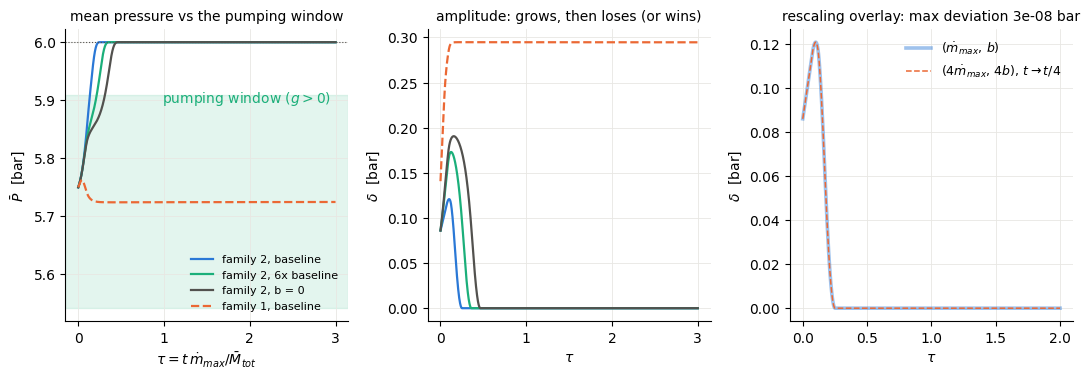

In [5]:
def run_traj(V0, mdot, b, tau_end=3.0, n=1500):
    global m_max, b_gas
    m_max, b_gas = mdot, b
    Mtot = P0 * (V0 + V0_pass) / (R * T0)
    t_end = tau_end * Mtot / mdot
    sol = solve_ivp(slow_rhs, (0.0, t_end), [P0 * V0 / (R * T0), P0, v0 / geom(P0, V0)[4]],
                    args=(V0,), method='LSODA', rtol=1e-8, atol=[1e-12, 1e-3, 1e-11],
                    dense_output=True, max_step=t_end / 1500)
    ta = np.linspace(0.0, t_end, n)
    Mb, Pb, a = sol.sol(ta)
    kcv = np.array([geom(p, V0)[2] for p in Pb])
    return ta * mdot / Mtot, Pb, kcv * np.maximum(a, 0.0) / A_neck

# pumping window: sign of T_in*N(u_in) + T0*N(u_out) (small-delta, Tbar = T0)
Ps = np.linspace(P_out + 2e3, P_in - 2.0, 3000)
h = 1.0
gsign = np.array([-(T_in * (reed_flow(P_in - p + h) - reed_flow(P_in - p - h))
                   + T0 * (reed_flow(p - P_out + h) - reed_flow(p - P_out - h))) for p in Ps])
iw = np.where(gsign > 0)[0]
win = (Ps[iw[0]], Ps[iw[-1]])
print('pumping window: %.3f .. %.3f bar' % (win[0] / 1e5, win[1] / 1e5))

cases = [('family 2, baseline', 2e-4, 1e-3, 0.005, BLUE, '-'),
         ('family 2, 6x baseline', 2e-4, 6e-3, 0.005, AQUA, '-'),
         ('family 2, b = 0', 2e-4, 1e-3, 1e-8, INK2, '-'),
         ('family 1, baseline', 1e-4, 1e-3, 0.005, ORANGE, '--')]
trajs = [(lab, *run_traj(V0, md, b), c, ls) for lab, V0, md, b, c, ls in cases]
m_max, b_gas = 0.001, 0.005

fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
fig.subplots_adjust(wspace=0.28)
ax = axs[0]
ax.axhspan(win[0] / 1e5, win[1] / 1e5, color=AQUA, alpha=0.12, zorder=0)
for lab, tau, Pb, dl, c, ls in trajs:
    ax.plot(tau, Pb / 1e5, color=c, ls=ls, lw=1.6, label=lab)
ax.axhline(P_in / 1e5, color=INK2, lw=0.8, ls=':')
ax.text(2.95, win[1] / 1e5 - 0.012, 'pumping window ($g>0$)', ha='right', color=AQUA)
ax.set_xlabel(r'$\tau = t\,\dot m_{max}/\bar M_{tot}$'); ax.set_ylabel(r'$\bar P$  [bar]')
ax.set_title('mean pressure vs the pumping window', fontsize=10)
ax.legend(frameon=False, fontsize=8, loc='lower right')
ax = axs[1]
for lab, tau, Pb, dl, c, ls in trajs:
    ax.plot(tau, dl / 1e5, color=c, ls=ls, lw=1.6)
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$\delta$  [bar]')
ax.set_title('amplitude: grows, then loses (or wins)', fontsize=10)
ax = axs[2]
t1, P1, d1 = run_traj(2e-4, 1e-3, 0.005, tau_end=2.0)
t4, P4, d4 = run_traj(2e-4, 4e-3, 0.020, tau_end=2.0)
m_max, b_gas = 0.001, 0.005
ax.plot(t1, d1 / 1e5, color=BLUE, lw=2.6, alpha=0.45, label=r'$(\dot m_{max},\,b)$')
ax.plot(t4, d4 / 1e5, color=ORANGE, lw=1.1, ls='--', label=r'$(4\dot m_{max},\,4b)$, $t\to t/4$')
ax.set_xlabel(r'$\tau$'); ax.set_ylabel(r'$\delta$  [bar]')
ax.set_title('rescaling overlay: max deviation %.0e bar' % (np.max(np.abs(d1 - d4)) / 1e5), fontsize=10)
ax.legend(frameon=False, fontsize=9)
for ax in axs:
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(color='#e8e7e3', lw=0.6)
plt.show()

## 5. The collapse test: boundaries for a continuum of geometries

Families 2–5 have no boundary, so to test the non-dimensionalization we need geometries that do. Sweep $V_{0,cv}$ finely below the critical volume $V^{*}$ (found by bisecting the undamped verdict) and bisect the critical $\dot m_{max}$ for each. Then compare the boundary expressed in the raw group $\Pi_1$ against the dressed $\Pi$.

In [6]:
tic = time.time()
# critical geometry: largest V0_cv whose undamped (b -> 0) system sustains
b_save, b_gas = b_gas, 1e-8
lo_v, hi_v = 1e-4, 2e-4
for _ in range(20):
    mid = 0.5 * (lo_v + hi_v)
    if classify(mid, 1e-3)[0]:
        lo_v = mid
    else:
        hi_v = mid
b_gas = b_save
Vstar = 0.5 * (lo_v + hi_v)
print('V* = %.4e m^3   (families 2-5 all sit above this)   [%.0f s]' % (Vstar, time.time() - tic))

V0_grid = np.array([3e-5, 4.5e-5, 6.5e-5, 8e-5, 1e-4, 1.2e-4, 1.4e-4, 1.6e-4, 1.75e-4, 1.85e-4])
rows = []
for V0 in V0_grid:
    mc = find_boundary(V0)
    fn = family_numbers(V0)
    rows.append(dict(V0_cv=V0, mdot_crit=mc, Q=fn['Q'], L=fn['L'],
                     Pi1_crit=Pi_raw(V0, mc, fn), Pi_crit=Pi_dressed(V0, mc, fn)))
    print('V0_cv = %.2e:  mdot_crit = %.3e kg/s' % (V0, mc))
m_max = 0.001
import pandas as pd
df = pd.DataFrame(rows)
df['Pi_crit*(1-V0/V*)'] = df.Pi_crit * (1 - df.V0_cv / Vstar)
print('[%.0f s]' % (time.time() - tic))
df.style.format({'V0_cv': '{:.2e}', 'mdot_crit': '{:.3e}', 'Q': '{:.0f}', 'L': '{:.3f}',
                 'Pi1_crit': '{:.3e}', 'Pi_crit': '{:.2f}', 'Pi_crit*(1-V0/V*)': '{:.3f}'})

V* = 1.9454e-04 m^3   (families 2-5 all sit above this)   [2 s]
V0_cv = 3.00e-05:  mdot_crit = 6.188e-05 kg/s
V0_cv = 4.50e-05:  mdot_crit = 1.008e-04 kg/s
V0_cv = 6.50e-05:  mdot_crit = 1.665e-04 kg/s
V0_cv = 8.00e-05:  mdot_crit = 2.361e-04 kg/s
V0_cv = 1.00e-04:  mdot_crit = 3.764e-04 kg/s
V0_cv = 1.20e-04:  mdot_crit = 6.036e-04 kg/s
V0_cv = 1.40e-04:  mdot_crit = 1.015e-03 kg/s
V0_cv = 1.60e-04:  mdot_crit = 1.928e-03 kg/s
V0_cv = 1.75e-04:  mdot_crit = 3.874e-03 kg/s
V0_cv = 1.85e-04:  mdot_crit = 8.603e-03 kg/s
[37 s]


AttributeError: The '.style' accessor requires jinja2

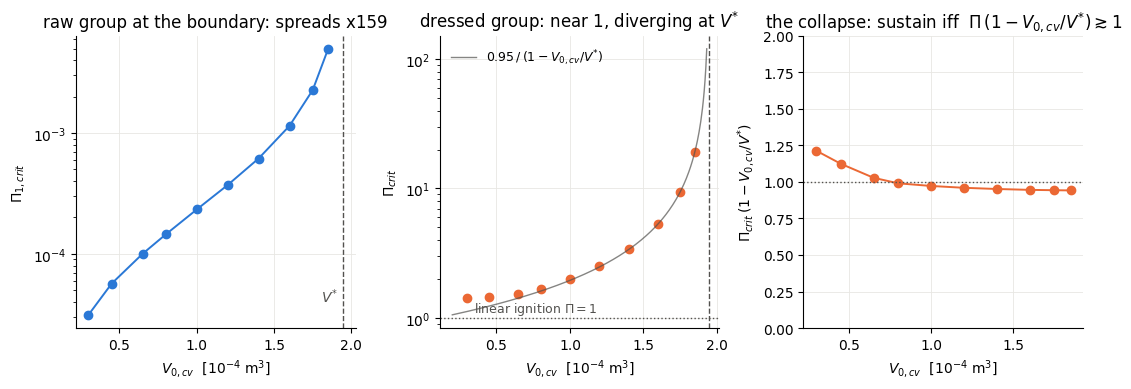

In [ ]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
fig.subplots_adjust(wspace=0.3)
Vs = df.V0_cv * 1e4
ax = axs[0]
ax.semilogy(Vs, df.Pi1_crit, 'o-', color=BLUE, lw=1.4)
ax.axvline(Vstar * 1e4, color=INK2, ls='--', lw=1)
ax.text(Vstar * 1e4 - 0.03, 4e-5, '$V^{*}$', ha='right', color=INK2)
ax.set_xlabel(r'$V_{0,cv}$  [$10^{-4}$ m$^3$]'); ax.set_ylabel(r'$\Pi_{1,crit}$')
sp = df.Pi1_crit.max() / df.Pi1_crit.min()
ax.set_title('raw group at the boundary: spreads x%.0f' % sp)
ax = axs[1]
ax.semilogy(Vs, df.Pi_crit, 'o', color=ORANGE)
vv = np.linspace(2e-5, 1.93e-4, 300)
C = np.mean(df.Pi_crit.values[-5:] * (1 - df.V0_cv.values[-5:] / Vstar))
ax.semilogy(vv * 1e4, C / (1 - vv / Vstar), '-', color=INK2, lw=1, alpha=0.7,
            label=r'$%.2f\,/\,(1 - V_{0,cv}/V^{*})$' % C)
ax.axhline(1.0, color=INK2, ls=':', lw=1)
ax.text(0.35, 1.1, r'linear ignition $\Pi = 1$', color=INK2, fontsize=9)
ax.axvline(Vstar * 1e4, color=INK2, ls='--', lw=1)
ax.set_xlabel(r'$V_{0,cv}$  [$10^{-4}$ m$^3$]'); ax.set_ylabel(r'$\Pi_{crit}$')
ax.set_title('dressed group: near 1, diverging at $V^{*}$')
ax.legend(frameon=False, fontsize=9, loc='upper left')
ax = axs[2]
ax.plot(Vs, df['Pi_crit*(1-V0/V*)'], 'o-', color=ORANGE, lw=1.4)
ax.axhline(1.0, color=INK2, ls=':', lw=1)
ax.set_ylim(0, 2)
ax.set_xlabel(r'$V_{0,cv}$  [$10^{-4}$ m$^3$]')
ax.set_ylabel(r'$\Pi_{crit}\,(1 - V_{0,cv}/V^{*})$')
ax.set_title('the collapse: sustain iff  $\\Pi\\,(1-V_{0,cv}/V^{*}) \\gtrsim 1$')
for ax in axs:
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(color='#e8e7e3', lw=0.6)
plt.show()

## 6. Spot checks against the full simulation

The map and the boundaries above come from the averaged model (a bisection takes ~5 s there; in the full model it would take hours). Here the full model votes at 8 points: brackets ±8% and ±22% around the family-1 boundary, ±20–25% around the boundary of the new $V_{0,cv} = 1.6\times10^{-4}$ family, and two "no boundary exists" claims at $6\times$ your baseline capacity. A run counts as sustained if the Hilbert envelope of $P - \bar P$ ends above $10^3$ Pa.

In [ ]:
tic = time.time()
mc16 = df.loc[np.isclose(df.V0_cv, 1.6e-4), 'mdot_crit'].iloc[0]
CHECKS = [(1.0e-4, 0.80 * mdot_crit_f1, 18.0), (1.0e-4, 0.92 * mdot_crit_f1, 18.0),
          (1.0e-4, 1.08 * mdot_crit_f1, 14.0), (1.0e-4, 1.25 * mdot_crit_f1, 14.0),
          (1.6e-4, 0.80 * mc16, 6.0), (1.6e-4, 1.25 * mc16, 6.0),
          (2.0e-4, 6.0e-3, 2.5), (5.0e-4, 6.0e-3, 2.5)]
frows, traces = [], {}
for V0, md, tend in CHECKS:
    m_max = md
    avg_verdict = classify(V0, md)[0]
    m_max = md
    t, P = run_full(V0, t_end=tend, n_eval=int(4000 * tend))
    Pbar, env = extract(t, P)
    full_verdict = env[-1] > 1e3
    frows.append(dict(V0_cv=V0, mdot=md, avg='SUST' if avg_verdict else 'dies',
                      full='SUST' if full_verdict else 'dies',
                      agree=avg_verdict == full_verdict,
                      env_end_Pa=env[-1], Pbar_end_bar=Pbar[-1] / 1e5))
    traces[(V0, md)] = (t, P, Pbar, env)
    print('V0 = %.1e  mdot = %.3e:  full says %-4s  (avg says %-4s)  [%.0f s]'
          % (V0, md, frows[-1]['full'], frows[-1]['avg'], time.time() - tic))
m_max = 0.001
dff = pd.DataFrame(frows)
print('\nagreement: %d / %d' % (dff.agree.sum(), len(dff)))
dff.style.format({'V0_cv': '{:.1e}', 'mdot': '{:.3e}', 'env_end_Pa': '{:.0f}', 'Pbar_end_bar': '{:.4f}'})

V0 = 1.0e-04  mdot = 3.011e-04:  full says dies  (avg says dies)  [6 s]


V0 = 1.0e-04  mdot = 3.463e-04:  full says dies  (avg says dies)  [12 s]


V0 = 1.0e-04  mdot = 4.065e-04:  full says SUST  (avg says SUST)  [18 s]


V0 = 1.0e-04  mdot = 4.705e-04:  full says SUST  (avg says SUST)  [23 s]


V0 = 1.6e-04  mdot = 1.542e-03:  full says dies  (avg says dies)  [27 s]


V0 = 1.6e-04  mdot = 2.409e-03:  full says SUST  (avg says SUST)  [29 s]


V0 = 2.0e-04  mdot = 6.000e-03:  full says dies  (avg says dies)  [32 s]


V0 = 5.0e-04  mdot = 6.000e-03:  full says dies  (avg says dies)  [34 s]

agreement: 8 / 8


,V0_cv,mdot,avg,full,agree,env_end_Pa,Pbar_end_bar
0,1.0e-04,3.011e-04,dies,dies,True,327,6.0000
1,1.0e-04,3.463e-04,dies,dies,True,328,6.0000
2,1.0e-04,4.065e-04,SUST,SUST,True,27269,5.7157
3,1.0e-04,4.705e-04,SUST,SUST,True,27745,5.7167
4,1.6e-04,1.542e-03,dies,dies,True,389,6.0000
5,1.6e-04,2.409e-03,SUST,SUST,True,29852,5.7171
6,2.0e-04,6.000e-03,dies,dies,True,450,6.0000
7,5.0e-04,6.000e-03,dies,dies,True,217,6.0000


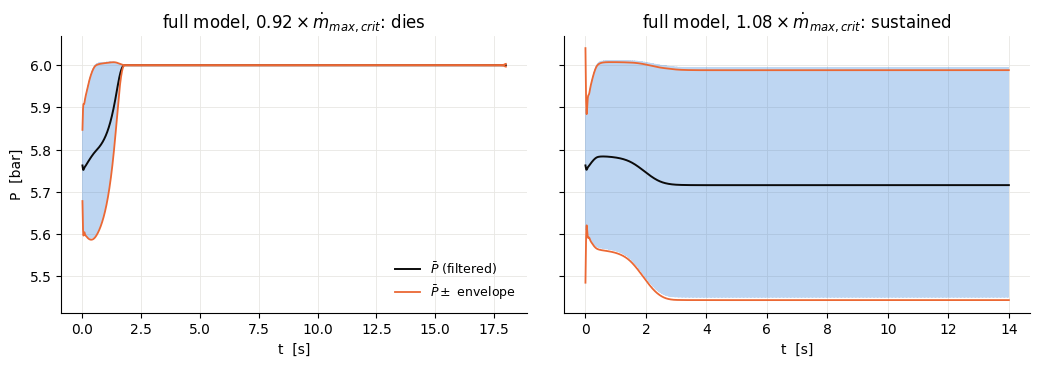

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
fig.subplots_adjust(wspace=0.08)
for ax, fac, lab in [(axs[0], 0.92, r'$0.92\times\dot m_{max,crit}$: dies'),
                     (axs[1], 1.08, r'$1.08\times\dot m_{max,crit}$: sustained')]:
    t, P, Pbar, env = traces[(1.0e-4, fac * mdot_crit_f1)]
    ax.plot(t, P / 1e5, color=BLUE, lw=0.25, alpha=0.30)
    ax.plot(t, Pbar / 1e5, color=INK, lw=1.4, label=r'$\bar P$ (filtered)')
    ax.plot(t, (Pbar + env) / 1e5, color=ORANGE, lw=1.3, label=r'$\bar P \pm$ envelope')
    ax.plot(t, (Pbar - env) / 1e5, color=ORANGE, lw=1.3)
    ax.set_xlabel('t  [s]'); ax.set_title('full model, ' + lab)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    ax.grid(color='#e8e7e3', lw=0.6)
axs[0].set_ylabel('P  [bar]'); axs[0].legend(frameon=False, fontsize=9, loc='lower right')
plt.show()

## 7. Summary, and how to use this

**The criterion.** Small oscillations about the launch state grow iff $\Pi = \gamma_E\, Q\, L\, \dfrac{P_0}{\Delta P_{max}}\, \dfrac{\tilde G\,\dot m_{max}}{\bar M_{cv}\,\omega_0} > 1$ — your group $\dot m_{max}/(\bar M\omega)$ times pressure leverage, gas-spring lever, quality factor, and the $O(1)$ valve-shape factor $\tilde G$. Sustained operation (surviving the charge-up race) empirically needs the stronger condition $\Pi\,(1 - V_{0,cv}/V^{*}) \gtrsim 1$, which held to ±15% across a 160-fold range of the raw group. Equivalently: $\dot m_{max,crit} = \dfrac{\bar M_{cv}\,\omega_0\,\Delta P_{max}}{\gamma_E\,Q\,L\,P_0\,\tilde G\,(1 - V_{0,cv}/V^{*})}$.

**Numbers for your sweep.** $V^{*} = 1.95\times10^{-4}$ m³. Family 1: boundary at $\dot m_{max,crit} \approx 3.8\times10^{-4}$ kg/s ($\Pi_{crit} = 2.0$); your baseline $10^{-3}$ kg/s is 2.7× above it. Families 2–5: $V_{0,cv} > V^{*}$, dead at every $\dot m_{max}$ — to make them run you must change *geometry* (or damping is not the issue: e.g. enlarge $A$, shrink $V_{0,cv}$, soften the passive spring), not valve capacity.

**Two design knobs, not one.** Because $\dot m_{max}$ and $b$ enter only as a ratio, "more valve" and "less friction" are the same knob; the second, independent knob is the race margin $1 - V_{0,cv}/V^{*}$, set by geometry through where the pumping window sits and how fast the amplitude can grow while crossing it.

**Caveats.** (i) $\Pi$ is evaluated at the launch state $(P_0, T_0)$; $\tilde G$ and the window move as $\bar P,\bar T$ drift. (ii) $V^{*}$ is specific to this valve law, pressure ladder, and the kick $v_0 = 5$ m/s — with $b = 0$ the race verdict can in principle depend on the kick size. (iii) The averaged model stands on the $\varepsilon \approx 10^{-2}$ timescale separation; its boundary was confirmed here by the full model to within ±8% (family 1). (iv) The reverse-flow branch of `reed_flow` is kept throughout, so dead cases land at exactly $P_{in}$.